# $L(2,\chi_{-3})$: historical construction and new trajectory

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import acb, arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, x2, x3, y0, y1, y2 = sp.symbols('x0 x1 x2 x3 y0 y1 y2')
target = lambda: 2/arb(3).sqrt()*acb.polylog(acb.exp_pi_i(acb(2)/3), 2).imag


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Zagier (2009)

[Paper](https://people.mpim-bonn.mpg.de/zagier/files/tex/AperylikeRecEqs/fulltext.pdf).

**CMF:** ${}_3F_2(4)$ · **Start:** $(0,0,\tfrac12;1,1)$ · **Direction:** $(-1,-1,0;0,0)$.
Here we use the **direct** walk. Its first column is
$(s_0,s_1,s_2)=(a_N,0,-9b_N)$, so the extraction is
$$\frac{p_N}{q_N}=\frac{-2s_2}{9s_0}=\frac{2b_N}{a_N}.$$

In [5]:
cmf = pFq(3, 2, 4)
half = sp.Rational(1, 2)
start = {x0: 0, x1: 0, x2: half, y0: 1, y1: 1}
trajectory = {x0: -1, x1: -1, x2: 0, y0: 0, y1: 0}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [-2 * W[2, 0] / (9 * W[0, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zagier (2009)'] = (DEPTHS, deltas)
accuracy['Zagier (2009)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.467075344739


## 2. New ${}_4F_3(\tfrac14)$ trajectory

[New Directions in Irrationality](https://arxiv.org/abs/2610.27799).

**CMF:** ${}_4F_3(\tfrac14)$ · **Start:**
$(\tfrac12,\tfrac12,\tfrac12,\tfrac12;\tfrac32,\tfrac32,\tfrac32)$ ·
**Direction:** $(5,7,6,8;17,18,8)$. We use the inverse-transpose walk. With
$c_j=s_j/s_0$, the extraction is
$$\frac{p_N}{q_N}=\frac{-16c_1-8}{-54c_1-108c_2-72c_3-9}.$$
At the start this readout equals $\bigl(3\psi_1(\tfrac13)-\psi_1(\tfrac56)\bigr)/36
=L(2,\chi_{-3})$ (paper, Appendix B).

In [7]:
cmf = pFq(4, 3, sp.Rational(1, 4)).dual()
half = sp.Rational(1, 2)
start = {x0: half, x1: half, x2: half, x3: half, y0: 3 * half, y1: 3 * half, y2: 3 * half}
trajectory = {x0: 5, x1: 7, x2: 6, x3: 8, y0: 17, y1: 18, y2: 8}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(16 * W[1, 0] + 8 * W[0, 0]) / (54 * W[1, 0] + 108 * W[2, 0] + 72 * W[3, 0] + 9 * W[0, 0])
                for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['New ${}_4F_3(1/4)$ trajectory'] = (DEPTHS, deltas)
accuracy['New ${}_4F_3(1/4)$ trajectory'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.060306098956


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

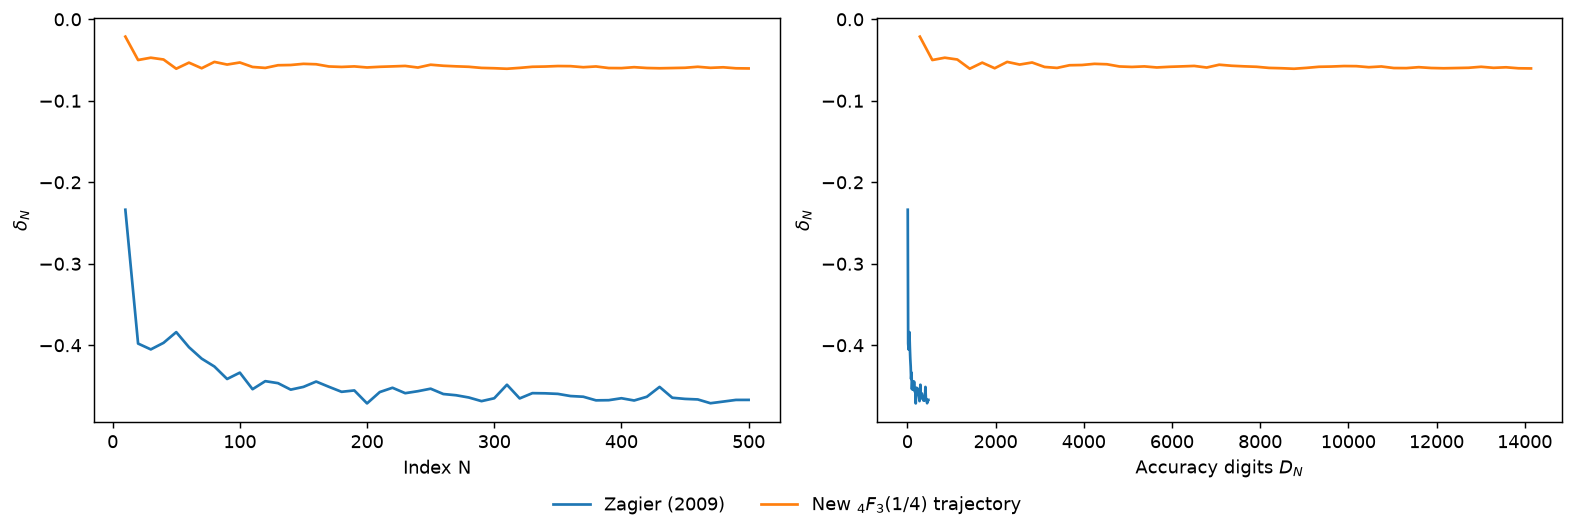

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [11]:
bounds = {
    'Zagier (2009)': '$\\delta=-0.47651$',
    'New ${}_4F_3(1/4)$ trajectory': '$\\delta\\approx-0.05909$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Zagier (2009) | $\delta=-0.47651$ | -0.467075344739 (N = 500) |
| New ${}_4F_3(1/4)$ trajectory | $\delta\approx-0.05909$ | -0.060306098956 (N = 500) |